In [1]:
from config import Settings, build_app_config
from system_prompts import SYSTEM_PROMPT1, SYSTEM_PROMPT2

config = build_app_config(Settings(input_excel_path="test_attributes.xlsx",
                                   output_excel_path="test_first_phase_table3.xlsx"))


In [2]:
from langchain.tools import tool

@tool
def convert_bar_to_mpa(value_bar: float) -> float:
    """Convert pressure from bar to megapascals (MPa). 1 bar = 0.1 MPa."""
    return round(value_bar * 0.1, 2)

@tool
def convert_psi_to_mpa(value_psi: float) -> float:
    """Convert pressure from psi to megapascals (MPa). 1 psi = 0.006895 MPa."""
    return round(value_psi * 0.006895, 2)

@tool
def convert_inch_to_mm(value_inch: float) -> float:
    """Convert length from inches to millimetres. 1 inch = 25.4 mm."""
    return round(value_inch * 25.4, 2)

@tool
def convert_lb_to_kg(value_lb: float) -> float:
    """Convert weight from pounds to kilograms. 1 lb = 0.4536 kg."""
    return round(value_lb * 0.4536, 2)

@tool
def convert_kelvin_to_celsius(value_k: float) -> float:
    """Convert temperature from Kelvin to Celsius."""
    return round(value_k - 273.15, 2)

@tool
def convert_fahrenheit_to_celsius(value_f: float) -> float:
    """Convert temperature from Fahrenheit to Celsius."""
    return round((value_f - 32) * 5 / 9, 2)

In [5]:
from langgraph.graph import START, StateGraph, MessagesState, END
from IPython.display import display, Image
import pandas
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from langchain.tools import tool
from langgraph.prebuilt import ToolNode, tools_condition
from typing import Literal, Annotated
from langchain_core.messages import HumanMessage, ToolMessage, RemoveMessage
from operator import add

class MessagesState(MessagesState):
    index_row_table: int
    attribute: str
    value: str
    new_rows: Annotated[list[dict], add]

def transform_value_loop(state: MessagesState) -> MessagesState:
    update: dict = {}

    if state["index_row_table"] != 0:
        new_row = {
            "Attribute": state["attribute"],
            "Value": state["value"],
            "Rules_Value": state["messages"][-1].content,
        }
        update["new_rows"] = [new_row]

    if config.data_frame.shape[0] > state["index_row_table"]:
        update["attribute"] = config.data_frame.iloc[state["index_row_table"]]["Attribute"]
        update["value"] = config.data_frame.iloc[state["index_row_table"]]["Value"]
        update["messages"] = [RemoveMessage(id=k.id) for k in state["messages"]]

    return update

def condition_edges_1(state: MessagesState) -> Literal["transform_value_row", "end_node"]:
    if state["index_row_table"] < config.data_frame.shape[0]:
        return "transform_value_row"
    else:
        return "end_node"

def condition_edges_2(state: MessagesState) -> Literal["tools", "transform_value_loop"]:
    last_message = state["messages"][-1]
    if getattr(last_message, "tool_calls", None):
        return "tools"
    return "transform_value_loop"



tools = [convert_bar_to_mpa, convert_psi_to_mpa, convert_inch_to_mm, convert_lb_to_kg, convert_kelvin_to_celsius, convert_fahrenheit_to_celsius]
llm_bind_tools = config.model.bind_tools(tools=tools)

def transform_value_row(state: MessagesState) -> MessagesState:
    """Retrieve information to help answer a query and return list of documents."""
    if state["messages"] and isinstance(state["messages"][-1], ToolMessage):
        new_inv = llm_bind_tools.invoke(state.get("messages") + [{"role": "system", "content": SYSTEM_PROMPT1}])
        return {"messages": [new_inv]}

    else:
        retrieved_documents = config.store.similarity_search(query = f"{state['attribute']}", k=2)
        candidate_headers = [doc.page_content for doc in retrieved_documents]
        candidates_text = "\n".join(f"{idx+1}. {header}" for idx, header in enumerate(candidate_headers))

        selection = config.router_model.invoke([
            {"role": "system", "content": SYSTEM_PROMPT2},
            {"role": "user", "content": f"Current attribute: {state['attribute']}\n\nCandidate section names:\n{candidates_text}"}
        ])
        selection = selection.content.strip()
        retrieved_document = next((item for item in retrieved_documents if item.page_content.strip() == selection), retrieved_documents[0])

        contexts = retrieved_document.metadata["text"]
        new_iteration = state.get("index_row_table") + 1
        inv = llm_bind_tools.invoke([{"role": "system", "content": SYSTEM_PROMPT1}, {"role": 'user', "content": f"Attribute: {state['attribute']}\nValue: {state['value']}\n\nRelevant rules:\n{contexts}"}])

        return {    "messages": [

        {"role": "user", "content": f"Attribute: {state['attribute']}\nValue: {state['value']}\n\nRelevant rules:\n{contexts}"},
        inv],
    "index_row_table": new_iteration}

def end_node(state: MessagesState) -> MessagesState:
    output_data_frame = pandas.DataFrame(state["new_rows"])
    output_data_frame.to_excel(config.settings.output_excel_path, index=False)
    return state

load_dotenv()

tools_node = ToolNode(tools)


builder = StateGraph(MessagesState)
builder.add_node(transform_value_loop)
builder.add_node(transform_value_row)
builder.add_node(end_node)
builder.add_node("tools", tools_node)
builder.add_edge(START, "transform_value_loop")
builder.add_conditional_edges("transform_value_loop", condition_edges_1)
builder.add_conditional_edges("transform_value_row", condition_edges_2)
builder.add_edge("tools", "transform_value_row")
builder.add_edge("end_node", END)

graph = builder.compile()

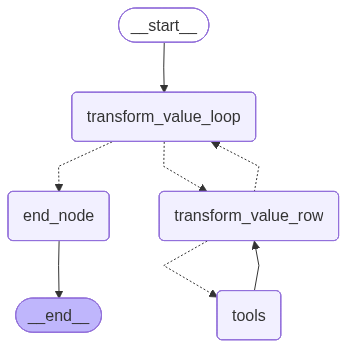

In [6]:
display(Image(graph.get_graph().draw_mermaid_png()))

In [7]:
result = graph.invoke({"messages": [], 'new_data_frame': pandas.DataFrame(columns=["Attribute", "Value", "Rules_Value"]), "index_row_table":0})

for f in result["messages"]:
    f.pretty_print()

================================ Human Message =================================

Attribute: Nominal pressure, psi
Value: 232 psi

Relevant rules:
All pressure values in the system must be expressed exclusively in megapascals (MPa).
The use of bar, atm, kgf/cm2, or psi is not permitted. If a source document contains
pressure in bar, convert it before entry: 1 bar equals 0.1 MPa. If the source uses
psi, apply the factor 1 psi = 0.006895 MPa. Nominal pressure must not exceed the
allowable rating for the given valve class. The standard nominal pressure series
includes PN 1.6, PN 2.5, and PN 4.0 MPa. Any value outside this series requires
explicit engineering justification. Reference: GOST 356-80, clause 3.1.
================================== Ai Message ==================================
Tool Calls:
  convert_psi_to_mpa (call_w0dhCgTmFrzK66UoM6l5Nl89)
 Call ID: call_w0dhCgTmFrzK66UoM6l5Nl89
  Args:
    value_psi: 232
================================= Tool Message =========================